# Learn value functions and generalized advantage estimation

This worked reference is validated on CPU. Accelerator compatibility requires a separate source review and target execution receipt. Use the execution matrix to review device selection and data ownership before adapting a separate target program.

- Fit a tabular value function from actual rollout observations and masked return targets, and report its error before and after optimization.
- Compute generalized advantages with a reverse scan over time and an independently hand-calculated multi-step example.
- Use the retained final observation to bootstrap a continuing task cutoff while stopping the trace across episode resets.
- Explain why the existing finite-horizon REINFORCE/PPO objective opts out of time-limit bootstrapping.

A policy-gradient update needs an estimate of how much better an action was than its state baseline. How can we learn that baseline from the same retained rollout, and what must happen to its target at a true terminal versus a collector time limit?

## The idea

Fit a small value table to returns observed in genuine trajectories, then compute GAE by combining one-step TD residuals with a reverse scan. Keep bootstrap permission and trace continuation as separate masks: a continuing-task cutoff can use the final pre-reset state value, while the trace must stop before the reset episode.

## One retained transition has two observations

For each action, keep the observation used to choose it and the actual observation returned by the transition. In the corridor collector these are `observation` and `next_observation`; the latter is saved before any reset. At a time limit, the row after the cutoff may begin a new episode at position 0 even though the final observation from the cutoff was position 3. A critic must evaluate position 3 for the bootstrap. The reset observation belongs to the next transition, not the previous transition's target.

The value table has one trainable scalar for each of the four positions. We fit it by minimizing squared error to sampled reward-to-go on live rows. Padding rows stay in the array for a fixed shape but contribute neither loss nor gradient. The fit is a real optimization over sampled trajectories; noisy returns mean the final error should fall without reaching zero.

### Pause and reason

At a collector cutoff, the next rollout row shows reset position 0 but the transition record says the final observation was position 3. Which observation supplies the bootstrap value?

<details><summary>Compare your reasoning</summary>

Use position 3, the actual transition result retained in `next_observation`. Position 0 is the start of another episode and must not enter the earlier episode's target.

</details>

## Bootstrapping and trace continuation answer different questions

A true terminal state has no future value, so its bootstrap mask is zero. A collector cutoff in a continuing task still has future value, so it can bootstrap from the final pre-reset observation. In both cases the recursive trace stops at the boundary. Otherwise an advantage from the new episode would flow backward through a reset. Padding also has a zero mask and contributes no value loss.

The project has a finite action budget: its objective is reward accumulated within those eight actions. For that objective, the horizon has no future value, so use `bootstrap_on_truncation=False`. Set it true only when truncation means the collector stopped a continuing task whose process would otherwise continue.

$$
\delta_t = r_t + \gamma\,m_t^{\mathrm{boot}} V(s_{t+1}) - V(s_t) \quad A_t = \delta_t + \gamma\lambda\,m_t^{\mathrm{trace}} A_{t+1}
$$

## Work the reverse scan by hand

Let $\gamma=0.5$, $\lambda=0.5$, and let $V(0)=0.5$, $V(1)=1$, $V(2)=2$, $V(3)=4$. The first transition has reward 1 from position 0 to 1, so $\delta_0=1+0.5(1)-0.5=1$. The second has reward 2 from position 1 and is cut off at final position 3, so $\delta_1=2+0.5(4)-1=3$. It bootstraps from position 3 but ends the trace. Thus $A_1=3$, then $A_0=1+0.5(0.5)(3)=1.75$. The reset observation in the next row is position 0 and has no effect on either value.

## A lower fit error is evidence of optimization, not policy quality

The fitted table estimates average sampled return for each observed position. It cannot represent time remaining, and it cannot predict the random outcome of an individual trajectory exactly. Read the error plot as training evidence for this small critic. It does not establish that a policy improved, that a neural critic works, or that a continuous-control agent is effective. To test policy improvement, the value estimate must be connected to an actor update and evaluated under held-out conditions.

## Define the rollout and return target

Import the local CPU dependencies, define the fixed-shape collector, and retain each transition’s actual next observation. Add the finite-horizon reward-to-go helper.

In [1]:
import jax
import jax.numpy as jnp
import numpy as np

def rollout(theta, key, batch_size=512, horizon=8):
    """Collect fixed-shape trajectories and retain each pre-reset next state."""
    reset_key, action_key = jax.random.split(key)
    position = jax.vmap(lambda subkey: jax.random.randint(subkey, (), 0, 2))(jax.random.split(reset_key, batch_size))
    elapsed = jnp.zeros((batch_size,), dtype=jnp.int32)
    done = jnp.zeros((batch_size,), dtype=jnp.bool_)
    time_keys = jax.random.split(action_key, horizon)

    def collect(carry, time_key):
        position, elapsed, done = carry
        observation = position
        active = ~done
        keys = jax.random.split(time_key, batch_size)
        probability = jax.nn.sigmoid(theta[jnp.minimum(position, 2)])
        action = jax.vmap(jax.random.bernoulli)(keys, probability).astype(jnp.int32)
        proposed = jnp.clip(position + 2 * action - 1, 0, 3)
        next_position = jnp.where(active, proposed, position)
        next_elapsed = elapsed + active.astype(jnp.int32)
        terminated = active & (next_position == 3)
        truncated = active & ~terminated & (next_elapsed >= horizon)
        reward = jnp.where(active, jnp.where(terminated, 1., -.01), 0.)
        next_done = done | terminated | truncated
        record = {
            "observation": observation,
            "next_observation": next_position,
            "reward": reward,
            "active": active,
            "terminated": terminated,
            "truncated": truncated,
        }
        return (next_position, next_elapsed, next_done), record

    final_state, records = jax.lax.scan(collect, (position, elapsed, done), time_keys)
    return final_state, records

def returns_to_go(rewards):
    """Compute undiscounted finite-horizon returns along the time axis."""
    return jnp.cumsum(rewards[::-1], axis=0)[::-1]

The collector stores `next_observation` before any reset and returns time-major records. No repository module is needed.

## Define and fit the tabular value function

Define a masked mean-squared objective and its gradient-update scan. Padded rows are sanitized before residual arithmetic and do not affect the denominator.

In [2]:
def value_loss(value_table, records, targets):
    """Masked MSE with fixed targets and padding sanitized before arithmetic."""
    active = jnp.asarray(records["active"], dtype=jnp.bool_)
    predictions = value_table[jnp.clip(records["observation"], 0, 3)]
    targets = jax.lax.stop_gradient(jnp.asarray(targets))
    safe_targets = jnp.where(active, targets, jnp.zeros_like(targets))
    residual = jnp.where(active, predictions - safe_targets, jnp.zeros_like(predictions))
    return jnp.sum(jnp.square(residual)) / jnp.maximum(jnp.sum(active), 1)


def fit_value_function(records, targets, updates=250, learning_rate=.1):
    """Fit one scalar per state and retain the initial and updated losses."""
    table = jnp.zeros((4,), dtype=jnp.float32)
    loss_fn = lambda candidate: value_loss(candidate, records, targets)
    initial = loss_fn(table)

    def update(candidate, _):
        _, gradient = jax.value_and_grad(loss_fn)(candidate)
        next_table = candidate - learning_rate * gradient
        return next_table, loss_fn(next_table)

    table, history = jax.lax.scan(update, table, None, length=updates)
    return table, jnp.concatenate((initial[None], history))

The four table entries correspond to positions. The target is fixed rollout reward-to-go; the optimizer changes the table through gradient descent.

## Define GAE and choose the reproducible policy

Implement reverse GAE with separate bootstrap and trace-continuation masks, then set the policy logits used by the example.

In [3]:
def generalized_advantage_estimate(records, value_table, gamma=.9, lam=.95,
                                   bootstrap_on_truncation=False):
    """Reverse GAE; bootstrap mask and trace-continuation mask stay separate."""
    observations = records["observation"]
    next_observations = records["next_observation"]
    active = records["active"].astype(jnp.bool_)
    terminated = records["terminated"].astype(jnp.bool_)
    truncated = records["truncated"].astype(jnp.bool_)
    values = value_table[jnp.clip(observations, 0, 3)]
    next_values = value_table[jnp.clip(next_observations, 0, 3)]
    bootstrap = ~(terminated | (truncated & ~jnp.asarray(bootstrap_on_truncation)))
    delta = records["reward"] + gamma * bootstrap.astype(values.dtype) * next_values - values
    delta = jnp.where(active, delta, 0.)
    next_active = jnp.concatenate((active[1:], jnp.zeros_like(active[:1])), axis=0)
    trace = active & ~(terminated | truncated) & next_active

    def reverse_step(carry, inputs):
        residual, continues = inputs
        advantage = residual + gamma * lam * continues.astype(residual.dtype) * carry
        return advantage, advantage

    reverse_values = jnp.zeros(observations.shape[1:], dtype=values.dtype)
    _, reverse_advantages = jax.lax.scan(
        reverse_step, reverse_values, (delta[::-1], trace[::-1]))
    return jnp.where(active, reverse_advantages[::-1], 0.)

theta = jnp.array([-.7, .3, 1.1])

A terminal or cutoff can stop the trace while a continuing-task cutoff may still bootstrap from its retained final observation. This finite-horizon example selects no bootstrap beyond its deadline.

## Collect a rollout and fit values

Collect seed 313 data, compute return targets, fit the table for 250 updates, and retain the full loss history.

In [4]:
_, rollout_records = rollout(theta, jax.random.key(313), batch_size=512, horizon=8)
targets = returns_to_go(rollout_records["reward"])

value_table, loss_history = fit_value_function(rollout_records, targets)

print("initial / final masked value MSE:", float(loss_history[0]), float(loss_history[-1]))
print("fitted V(position 0..3):", np.asarray(value_table).round(4))

initial / final masked value MSE: 0.4650774896144867 0.21788980066776276
fitted V(position 0..3): [0.2825 0.5563 0.8614 0.    ]


Both the initial and updated errors are retained so the exercise can inspect actual learning rather than a hard-coded expected answer.

## Estimate GAE and prepare the learning plot

Estimate advantages with the finite-horizon setting, check their shape and finiteness, and build plot data from the retained loss history.

In [5]:
advantages = generalized_advantage_estimate(
    rollout_records, value_table, gamma=.9, lam=.95,
    bootstrap_on_truncation=False)
print("initial / final masked value MSE:", float(loss_history[0]), float(loss_history[-1]))
print("fitted V(position 0..3):", np.asarray(value_table).round(4))
print("GAE shape:", advantages.shape, "all finite:", bool(jnp.all(jnp.isfinite(advantages))))

visual_data = {
    "kind": "line",
    "x": list(range(len(loss_history))),
    "xlabel": "gradient updates",
    "ylabel": "masked value prediction MSE",
    "series": [{"label": "sampled rollout targets, seed 313", "y": np.asarray(loss_history).tolist()}],
}

initial / final masked value MSE: 0.4650774896144867 0.21788980066776276
fitted V(position 0..3): [0.2825 0.5563 0.8614 0.    ]
GAE shape: (8, 512) all finite: True


Every plotted point is a measured masked-MSE value from this run. The four-state critic and finite corridor do not demonstrate actor improvement or continuous control.

## Run the example

In [6]:
"""Self-contained CPU example: tabular value fitting and masked GAE."""

import jax
import jax.numpy as jnp
import numpy as np

def rollout(theta, key, batch_size=512, horizon=8):
    """Collect fixed-shape trajectories and retain each pre-reset next state."""
    reset_key, action_key = jax.random.split(key)
    position = jax.vmap(lambda subkey: jax.random.randint(subkey, (), 0, 2))(jax.random.split(reset_key, batch_size))
    elapsed = jnp.zeros((batch_size,), dtype=jnp.int32)
    done = jnp.zeros((batch_size,), dtype=jnp.bool_)
    time_keys = jax.random.split(action_key, horizon)

    def collect(carry, time_key):
        position, elapsed, done = carry
        observation = position
        active = ~done
        keys = jax.random.split(time_key, batch_size)
        probability = jax.nn.sigmoid(theta[jnp.minimum(position, 2)])
        action = jax.vmap(jax.random.bernoulli)(keys, probability).astype(jnp.int32)
        proposed = jnp.clip(position + 2 * action - 1, 0, 3)
        next_position = jnp.where(active, proposed, position)
        next_elapsed = elapsed + active.astype(jnp.int32)
        terminated = active & (next_position == 3)
        truncated = active & ~terminated & (next_elapsed >= horizon)
        reward = jnp.where(active, jnp.where(terminated, 1., -.01), 0.)
        next_done = done | terminated | truncated
        record = {
            "observation": observation,
            "next_observation": next_position,
            "reward": reward,
            "active": active,
            "terminated": terminated,
            "truncated": truncated,
        }
        return (next_position, next_elapsed, next_done), record

    final_state, records = jax.lax.scan(collect, (position, elapsed, done), time_keys)
    return final_state, records

def returns_to_go(rewards):
    """Compute undiscounted finite-horizon returns along the time axis."""
    return jnp.cumsum(rewards[::-1], axis=0)[::-1]

def value_loss(value_table, records, targets):
    """Masked MSE with fixed targets and padding sanitized before arithmetic."""
    active = jnp.asarray(records["active"], dtype=jnp.bool_)
    predictions = value_table[jnp.clip(records["observation"], 0, 3)]
    targets = jax.lax.stop_gradient(jnp.asarray(targets))
    safe_targets = jnp.where(active, targets, jnp.zeros_like(targets))
    residual = jnp.where(active, predictions - safe_targets, jnp.zeros_like(predictions))
    return jnp.sum(jnp.square(residual)) / jnp.maximum(jnp.sum(active), 1)


def fit_value_function(records, targets, updates=250, learning_rate=.1):
    """Fit one scalar per state and retain the initial and updated losses."""
    table = jnp.zeros((4,), dtype=jnp.float32)
    loss_fn = lambda candidate: value_loss(candidate, records, targets)
    initial = loss_fn(table)

    def update(candidate, _):
        _, gradient = jax.value_and_grad(loss_fn)(candidate)
        next_table = candidate - learning_rate * gradient
        return next_table, loss_fn(next_table)

    table, history = jax.lax.scan(update, table, None, length=updates)
    return table, jnp.concatenate((initial[None], history))

def generalized_advantage_estimate(records, value_table, gamma=.9, lam=.95,
                                   bootstrap_on_truncation=False):
    """Reverse GAE; bootstrap mask and trace-continuation mask stay separate."""
    observations = records["observation"]
    next_observations = records["next_observation"]
    active = records["active"].astype(jnp.bool_)
    terminated = records["terminated"].astype(jnp.bool_)
    truncated = records["truncated"].astype(jnp.bool_)
    values = value_table[jnp.clip(observations, 0, 3)]
    next_values = value_table[jnp.clip(next_observations, 0, 3)]
    bootstrap = ~(terminated | (truncated & ~jnp.asarray(bootstrap_on_truncation)))
    delta = records["reward"] + gamma * bootstrap.astype(values.dtype) * next_values - values
    delta = jnp.where(active, delta, 0.)
    next_active = jnp.concatenate((active[1:], jnp.zeros_like(active[:1])), axis=0)
    trace = active & ~(terminated | truncated) & next_active

    def reverse_step(carry, inputs):
        residual, continues = inputs
        advantage = residual + gamma * lam * continues.astype(residual.dtype) * carry
        return advantage, advantage

    reverse_values = jnp.zeros(observations.shape[1:], dtype=values.dtype)
    _, reverse_advantages = jax.lax.scan(
        reverse_step, reverse_values, (delta[::-1], trace[::-1]))
    return jnp.where(active, reverse_advantages[::-1], 0.)

theta = jnp.array([-.7, .3, 1.1])

_, rollout_records = rollout(theta, jax.random.key(313), batch_size=512, horizon=8)
targets = returns_to_go(rollout_records["reward"])

value_table, loss_history = fit_value_function(rollout_records, targets)

print("initial / final masked value MSE:", float(loss_history[0]), float(loss_history[-1]))
print("fitted V(position 0..3):", np.asarray(value_table).round(4))

advantages = generalized_advantage_estimate(
    rollout_records, value_table, gamma=.9, lam=.95,
    bootstrap_on_truncation=False)
print("initial / final masked value MSE:", float(loss_history[0]), float(loss_history[-1]))
print("fitted V(position 0..3):", np.asarray(value_table).round(4))
print("GAE shape:", advantages.shape, "all finite:", bool(jnp.all(jnp.isfinite(advantages))))

visual_data = {
    "kind": "line",
    "x": list(range(len(loss_history))),
    "xlabel": "gradient updates",
    "ylabel": "masked value prediction MSE",
    "series": [{"label": "sampled rollout targets, seed 313", "y": np.asarray(loss_history).tolist()}],
}


initial / final masked value MSE: 0.4650774896144867 0.21788980066776276
fitted V(position 0..3): [0.2825 0.5563 0.8614 0.    ]
initial / final masked value MSE: 0.4650774896144867 0.21788980066776276
fitted V(position 0..3): [0.2825 0.5563 0.8614 0.    ]
GAE shape: (8, 512) all finite: True


Expected: A four-entry value table, its retained masked-MSE history, and time-major GAE advantages from one sampled finite-horizon rollout.

## Value error falls while the table learns sampled returns

Predict: Will the error reach zero, and does a decreasing critic loss prove that the policy improved?

CPU computation; rerun to recompute the data.

Run the cells below to produce the figure, then follow the walkthrough beneath it.

In [7]:
visual_data = {'kind':'line','x':list(range(len(loss_history))),'xlabel':'gradient updates','ylabel':'masked value prediction MSE','series':[{'label':'sampled rollout, seed 313','y':np.asarray(loss_history).tolist()}]}

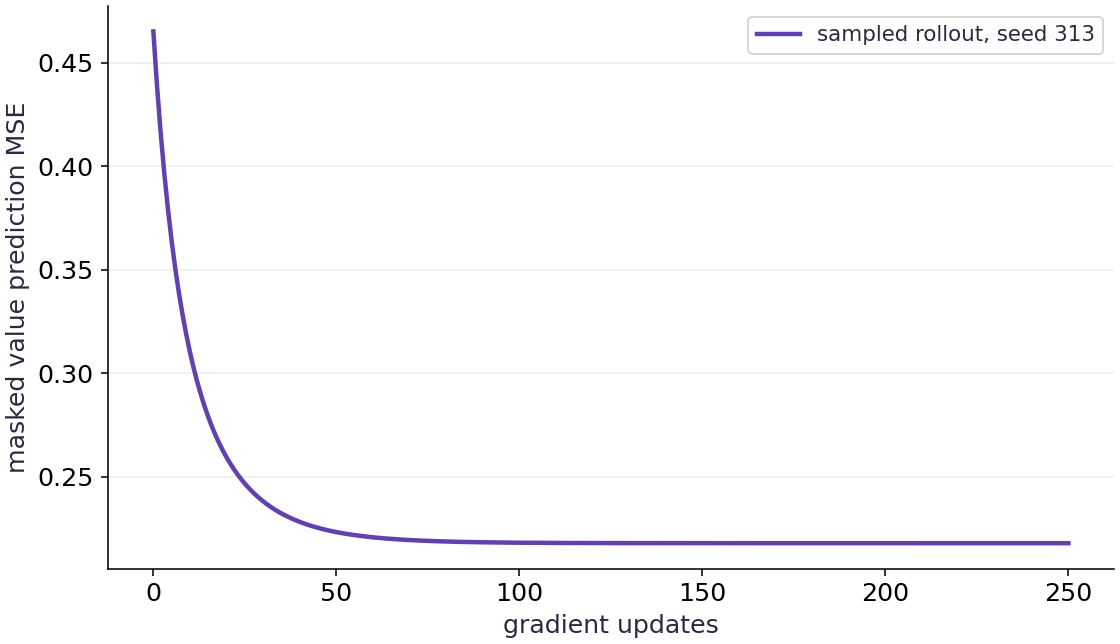

In [8]:
# Render the figure from the data computed above. Change the data experiment and rerun.
import matplotlib.pyplot as plt
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 13, 'axes.labelcolor': '#30273e', 'text.color': '#30273e'})
def draw_panel(ax, data):
    import numpy as np
    palette = ['#6240ad', '#087c83', '#bc532c', '#405d9d']
    kind = data['kind']
    if kind in ('heatmap', 'field'):
        a = np.asarray(data['values'], dtype=float)
        assert a.ndim == 2 and np.isfinite(a).all()
        kw = {'cmap': 'PuOr' if data.get('diverging') else 'Purples', 'aspect': 'auto'}
        if kind == 'field':
            kw.update(extent=data['extent'], origin='lower', vmin=0, vmax=1)
        elif data.get('diverging'):
            limit = max(float(np.abs(a).max()), 1e-10)
            kw.update(vmin=-limit, vmax=limit)
        if data.get('scale') == 'probability' or data['unit'] in ('attention weight', 'next-token probability', 'masked-token probability'):
            kw.update(vmin=0, vmax=1)
        categorical = data.get('scale') == 'categorical' or any(name in data['unit'] for name in ('device ID','program ID'))
        if categorical:
            from matplotlib.colors import ListedColormap, BoundaryNorm
            from matplotlib import colormaps
            ids=np.unique(a).astype(int)
            boundaries=np.r_[ids[0]-.5,(ids[:-1]+ids[1:])/2,ids[-1]+.5]
            kw.update(cmap=ListedColormap([colormaps['tab20'](i) for i in range(len(ids))]), norm=BoundaryNorm(boundaries,len(ids)))
        im = ax.imshow(a, **kw)
        ax.figure.colorbar(im, ax=ax, shrink=0.8, label=data['unit'], **({'ticks':ids} if categorical else {}))
        if kind == 'heatmap':
            if a.size <= 32:
                mid = (float(a.min()) + float(a.max())) / 2
                for (i, j), value in np.ndenumerate(a):
                    rgb=im.cmap(im.norm(value))[:3]
                    luminance=sum(c*w for c,w in zip(rgb,[0.2126,0.7152,0.0722]))
                    ax.text(j, i, f'{value:.3g}', ha='center', va='center', fontsize=11,
                            color='white' if luminance < 0.5 else '#20202c')
            ax.set_xticks(range(a.shape[1]), data.get('columns', [str(i) for i in range(a.shape[1])]))
            ax.set_yticks(range(a.shape[0]), data.get('rows', [str(i) for i in range(a.shape[0])]))
            if a.shape[1] > 5: ax.tick_params(axis='x', labelsize=11)
        else:
            pts = np.asarray(data['points']); labels = np.asarray(data['labels'])
            for label, marker in [(0, 'o'), (1, '^')]:
                selected = pts[labels == label]
                ax.scatter(selected[:, 0], selected[:, 1], label=f'observed label {label}', marker=marker,
                           s=38, facecolors='white' if label == 0 else '#f4b547', edgecolors='#272238', linewidths=1)
            ax.legend(loc='upper left', fontsize=10)
    elif kind in ('line', 'bar'):
        series = data['series']
        x = np.asarray(data.get('x', list(range(len(data.get('labels', []))))))
        assert len(x) and np.isfinite(x).all()
        for i, s in enumerate(series):
            y = np.asarray(s['y'], dtype=float)
            assert y.shape == x.shape and np.isfinite(y).all(), s['label']
            if data.get('yscale') == 'log': assert (y > 0).all()
            if kind == 'line':
                ax.plot(x, y, color=palette[i % len(palette)], label=s['label'], linewidth=2.3,
                        linestyle=['-', '--', '-.', ':'][i % 4], marker='o' if len(x) <= 25 else None, markersize=3)
            else:
                width = 0.78 / len(series)
                bars = ax.bar(x + (i - (len(series)-1)/2)*width, y, width, label=s['label'], color=palette[i % len(palette)])
                if len(x)*len(series) <= 12: ax.bar_label(bars, fmt='%.3g', fontsize=10, padding=3)
        if kind == 'bar':
            ax.set_xticks(x, data['labels'])
            ax.margins(y=0.17)
            if any(len(t) > 13 for t in data['labels']): ax.tick_params(axis='x', labelrotation=15, labelsize=11)
        if data.get('xscale'): ax.set_xscale(data['xscale'])
        if data.get('yscale'): ax.set_yscale(data['yscale'], **({'linthresh':data.get('linthresh',2)} if data['yscale']=='symlog' else {}))
        for marker in data.get('markers',[]):
            ax.scatter([marker['x']],[marker['y']],color='#bc532c',s=45,zorder=5)
            ax.annotate(marker['label'],(marker['x'],marker['y']),xytext=(-85,12),textcoords='offset points',fontsize=10)
        for boundary in data.get('boundaries', []): ax.axvline(boundary, color='#716e7b', linestyle=':', linewidth=1)
        ax.grid(axis='y', alpha=0.2)
        ax.legend(fontsize=11, loc='best')
    elif kind == 'vectors':
        for i, arrow in enumerate(data['arrows']):
            start = np.asarray(arrow['start']); end = np.asarray(arrow['end'])
            ax.annotate('', xy=end, xytext=start, arrowprops={'arrowstyle':'->','color':palette[i], 'lw':2.8})
            mid=(start+end)/2
            ax.annotate(arrow['label'], mid, xytext=(7,7), textcoords='offset points', color=palette[i])
        ax.set(xlim=(-0.7,4.5),ylim=(-0.7,5),xlabel='first coordinate',ylabel='second coordinate')
        ax.set_aspect('equal'); ax.grid(alpha=0.2)
    elif kind == 'flow':
        from matplotlib.patches import FancyBboxPatch
        nodes=data['nodes']; ax.set(xlim=(0,1),ylim=(0,len(nodes))); ax.axis('off')
        if data.get('layout') == 'merge':
            import textwrap
            for i,label in enumerate(nodes[:3]):
                x=0.02+i*0.33
                ax.add_patch(FancyBboxPatch((x,3.7),0.29,1.0,boxstyle='round,pad=0.015',facecolor='#f0eafa',edgecolor='#6240ad'))
                ax.text(x+0.145,4.2,textwrap.fill(label,20),ha='center',va='center',fontsize=11)
                ax.annotate('',(0.5,2.8),(x+0.145,3.67),arrowprops={'arrowstyle':'->','color':'#6240ad'})
            for y,label in [(2.4,nodes[3]),(0.9,nodes[4])]:
                ax.add_patch(FancyBboxPatch((0.08,y-0.35),0.84,0.7,boxstyle='round,pad=0.025',facecolor='#f0eafa',edgecolor='#6240ad'))
                ax.text(0.5,y,label,ha='center',va='center',fontsize=12)
            ax.annotate('',(0.5,1.3),(0.5,2.0),arrowprops={'arrowstyle':'->','color':'#6240ad'})
        else:
            for i, label in enumerate(nodes):
                y=len(nodes)-i-0.5
                ax.add_patch(FancyBboxPatch((0.08,y-0.3),0.84,0.6,boxstyle='round,pad=0.025',facecolor='#f0eafa',edgecolor='#6240ad'))
                ax.text(0.5,y,label,ha='center',va='center',fontsize=12)
                if i<len(nodes)-1: ax.annotate('',(0.5,y-0.67),(0.5,y-0.32),arrowprops={'arrowstyle':'->','color':'#6240ad'})
    else: raise ValueError(f'Unknown figure kind: {kind}')
    if data.get('xlabel'): ax.set_xlabel(data['xlabel'])
    if data.get('ylabel'): ax.set_ylabel(data['ylabel'])
    if data.get('title'): ax.set_title(data['title'], loc='left', fontsize=12, pad=12)
    for spine in ('top','right'): ax.spines[spine].set_visible(False)


def draw_mechanism(ax, diagram):
    """Draw a source-authored conceptual/analytic mechanism, never measured data."""
    import numpy as np
    from matplotlib.patches import FancyBboxPatch, Rectangle, Circle, Ellipse
    panel = diagram['panel']
    kind = panel['kind']
    colors = {'data':('#eef3ff','#3559a8'), 'state':('#f0eafa','#6240ad'),
              'fixed':('#f1f3f5','#536273'), 'result':('#e5f4ee','#17735c'),
              'warning':('#fff0e6','#a64d20')}
    if kind == 'graph':
        ax.set(xlim=(0,panel.get('width',10)),ylim=(panel.get('height',8),0))
        ax.axis('off')
        nodes={node['id']:node for node in panel['nodes']}
        for edge in panel['edges']:
            a,b=nodes[edge['from']],nodes[edge['to']]
            side_a=edge.get('exit','bottom'); side_b=edge.get('enter','top')
            def port(node,side):
                x,y=node['x'],node['y']; w,h=node.get('w',3),node.get('h',.8)
                return {'top':(x,y-h/2),'bottom':(x,y+h/2),'left':(x-w/2,y),'right':(x+w/2,y)}[side]
            start,end=port(a,side_a),port(b,side_b)
            ax.annotate('',xy=end,xytext=start,arrowprops={'arrowstyle':'-|>','color':'#536273','lw':1.7,'connectionstyle':edge.get('curve','arc3,rad=0')},zorder=1)
            if edge.get('label'):
                tx,ty=edge.get('labelAt',((start[0]+end[0])/2,(start[1]+end[1])/2))
                ax.text(tx,ty,edge['label'],ha='center',va='center',fontsize=10,color='#394658',bbox={'facecolor':'white','edgecolor':'none','pad':2},zorder=4)
        for node in panel['nodes']:
            fill,stroke=colors[node.get('tone','data')]
            x,y=node['x'],node['y'];w,h=node.get('w',3),node.get('h',.8)
            ax.add_patch(FancyBboxPatch((x-w/2,y-h/2),w,h,boxstyle='round,pad=0.02,rounding_size=0.07',facecolor=fill,edgecolor=stroke,lw=1.5,zorder=2))
            ax.text(x,y,node['label'],ha='center',va='center',fontsize=node.get('fontSize',12),color='#172334',zorder=3)
    elif kind == 'table':
        ax.axis('off')
        table=ax.table(cellText=panel['rows'],colLabels=panel['headers'],cellLoc='center',loc='center',colWidths=panel.get('widths'))
        table.auto_set_font_size(False);table.set_fontsize(12);table.scale(1,2.7)
        for (row,col),cell in table.get_celld().items():
            cell.set_edgecolor('#ccd3df')
            cell.set_facecolor('#e9e4f5' if row==0 else ('#f4f7fb' if row%2 else '#ffffff'))
            cell.set_text_props(color='#172334',weight='bold' if row==0 else 'normal')
    elif kind == 'clipping':
        ax.add_patch(Circle((0,0),2.5,fill=False,edgecolor='#17735c',linestyle='--',lw=1.8))
        ax.add_patch(Rectangle((-2.5,-2.5),5,5,fill=False,edgecolor='#a64d20',linestyle=':',lw=1.8))
        for end,color,label,offset in [((3,4),'#3559a8','Original (3, 4)',(8,5)),((1.5,2),'#17735c','Norm clip (1.5, 2)',(-126,-16)),((2.5,2.5),'#a64d20','Coordinate clip (2.5, 2.5)',(8,-2))]:
            ax.annotate('',xy=end,xytext=(0,0),arrowprops={'arrowstyle':'-|>','color':color,'lw':2.6})
            ax.annotate(label,end,xytext=offset,textcoords='offset points',color=color,fontsize=11)
        ax.set(xlim=(-3,5.8),ylim=(-3,4.8),xlabel='gradient coordinate 1',ylabel='gradient coordinate 2')
        ax.set_aspect('equal');ax.grid(alpha=.15)
    elif kind == 'patches':
        ax.set(xlim=(-.1,4.1),ylim=(4.1,-.1));ax.set_aspect('equal');ax.axis('off')
        for i in range(4):
            x,y=(i%2)*2,(i//2)*2
            visible=i in [0,3]
            ax.add_patch(Rectangle((x,y),2,2,facecolor='#e5f4ee' if visible else '#fff0e6',edgecolor='#17735c' if visible else '#a64d20',hatch=None if visible else '///',lw=2))
            ax.text(x+1,y+1,f'Patch {i}\n'+('visible input' if visible else 'hidden target'),ha='center',va='center',fontsize=14,bbox={'facecolor':'white','edgecolor':'none','alpha':.94,'pad':5})
        for a in [1,3]:
            ax.axhline(a,color='#172334',alpha=.25,lw=.7);ax.axvline(a,color='#172334',alpha=.25,lw=.7)
    elif kind == 'receptive-field':
        ax.set(xlim=(-.15,5.15),ylim=(5.15,-.15));ax.set_aspect('equal');ax.axis('off')
        for row in range(5):
            for col in range(5):
                selected=1<=row<=3 and 1<=col<=3
                ax.add_patch(Rectangle((col,row),1,1,facecolor='#e9e4f5' if selected else '#f4f7fb',edgecolor='#a6afc1',lw=1))
                ax.text(col+.5,row+.5,f'{row},{col}',ha='center',va='center',fontsize=12)
        ax.add_patch(Rectangle((1,1),3,3,fill=False,edgecolor='#6240ad',lw=3))
        ax.set_title('One 3 × 3 receptive field inside a 5 × 5 input',fontsize=13,pad=12)
    elif kind == 'covariance':
        for covariance,color,label in [(np.array([[1,.8],[.8,1]]),'#6240ad','Correlated covariance'),(np.eye(2),'#17735c','Same marginals, zero covariance')]:
            eig,vec=np.linalg.eigh(covariance);order=np.argsort(eig)[::-1];eig=eig[order];vec=vec[:,order]
            angle=np.degrees(np.arctan2(vec[1,0],vec[0,0]))
            ax.add_patch(Ellipse((0,0),2*np.sqrt(eig[0]),2*np.sqrt(eig[1]),angle=angle,fill=False,lw=2.5,edgecolor=color,label=label))
        ax.set(xlim=(-1.8,1.8),ylim=(-1.8,1.8),xlabel='first variable',ylabel='second variable')
        ax.set_aspect('equal');ax.grid(alpha=.2);ax.legend(loc='upper center',bbox_to_anchor=(.5,-.14),fontsize=10)
    elif kind == 'timeline':
        ax.set(xlim=(0,10),ylim=(-.7,2.7),yticks=[0,1,2],yticklabels=['Host','Device','Measurement'])
        for start,length,y,label,color in [(0,1,0,'dispatch','#3559a8'),(1,6,1,'device work','#6240ad'),(1,6,0,'wait for result','#a64d20'),(0,7,2,'completed-result interval','#17735c')]:
            ax.barh(y,length,left=start,height=.45,color=color,alpha=.18)
            ax.text(start+length/2,y,label,ha='center',va='center',fontsize=11)
        ax.axvline(7,color='#536273',linestyle='--');ax.text(7.1,.5,'result ready',fontsize=11)
        ax.set_xlabel('conceptual order; lengths are not measured durations')
        ax.invert_yaxis()
    else:
        raise ValueError(f'Unknown mechanism kind: {kind}')

panels = visual_data.get('panels', [visual_data])
fig, axes = plt.subplots(len(panels), 1, figsize=(8, 4.6 * len(panels)), squeeze=False, layout='constrained')
for ax, panel in zip(axes[:, 0], panels):
    draw_panel(ax, panel)
plt.show()

### Read the figure

The line plots the masked mean-squared error after each gradient update on 512 episodes collected with seed 313. It falls from about 0.4651 to 0.2179. The residual error is expected because the four-entry table predicts a mean and the returns are stochastic. This plot measures critic fit only.

### Connect it to the computation

Every plotted point comes from `fit_value_function` on retained rollout data. The task's existing policy objectives and their exact-return evaluation remain separate; the critic extension has no continuous-control or actor-improvement claim.

## Predict the time-limit target

Predict: If gamma is 0.5, reward is 2, V(position 1)=1 and the final pre-reset observation is position 3 with value 4, what is the TD residual?

In [9]:
gamma = .5
reward, current_value, final_value = 2., 1., 4.
delta = reward + gamma * final_value - current_value
assert delta == 3.
print('cutoff residual:', delta)

cutoff residual: 3.0


Expected: cutoff residual: 3.0

The old episode's final observation supplies the next value. The reset state in the following row is excluded from this transition.

## Train the value table on a retained rollout

Predict: Will fitting four shared state values drive error to zero when targets are sampled returns?

In [10]:
_, value_records = rollout(jnp.array([-.7,.3,1.1]), jax.random.key(313), 512, 8)
value_targets = returns_to_go(value_records['reward'])
value_table, value_history = fit_value_function(value_records, value_targets, 250, .1)
assert value_history[-1] < value_history[0] * .7
print('initial / final MSE:', float(value_history[0]), float(value_history[-1]))
print('V table:', np.asarray(value_table).round(4).tolist())

initial / final MSE: 0.4650774896144867 0.21788980066776276
V table: [0.2824999988079071, 0.5562999844551086, 0.8614000082015991, 0.0]


Expected: CPU JAX 0.9.2, seed 313: initial MSE 0.465077; final MSE 0.217890; fitted values [0.2825, 0.5563, 0.8614, 0.0].

The loss falls through gradient updates on actual sampled episodes. It remains positive because a four-state table cannot predict the stochastic return of every individual trajectory.

## Your exercise

Change the collection key from 313 to 314. Before running, predict which of the fitted values and final MSE should remain identical. Then retain both error histories and explain why changed trajectories should change the fitted table.

### How to write this exercise — Step-by-step recipe & starter scaffold

**Inputs:**
- A policy, an explicit collection key, and a retained rollout with `observation`, `next_observation`, and `active`.
- A changed collection key 314 after the recorded seed 313 run.
- The project’s return-to-go and value-fit functions.

**Outputs:**
- The fitted four-state value table and initial/per-update masked-MSE history.
- A comparison that keeps both seed-specific fits visible.

**Invariants to check:**
- Only active transitions contribute to value loss.
- The fit uses sampled rollout targets and reports real optimization error.
- Different collection keys can produce different trajectories and fitted values.

**Hints:**
- Build targets from the collected reward array.
- Keep the retained `next_observation` for the later GAE step.
- Compare final errors without expecting stochastic targets to produce zero error.

**Starter code scaffold (fill in the TODOs):**

```python
import jax
import jax.numpy as jnp

def fit_changed_rollout(theta, seed, rollout, returns_to_go, fit_value_function):
    # TODO: collect a new rollout using the supplied seed
    final_state, records = ...
    # TODO: form targets and fit the state-value table
    targets = ...
    value_table, loss_history = ...
    # TODO: return the learned table and retained error history
    raise NotImplementedError
```

In [11]:
# Write your attempt here (uncomment and fill in the TODOs below):


## Reference solution

Try your own implementation first.

In [12]:
# Refit from a changed collection key and retain both complete learning records.
seed313_records = rollout_records
seed313_targets = targets
seed313_table = value_table
seed313_history = loss_history
seed314_final_state, seed314_records = rollout(
    theta, jax.random.key(314), batch_size=512, horizon=8
)
seed314_targets = returns_to_go(seed314_records["reward"])
seed314_table, seed314_history = fit_value_function(
    seed314_records, seed314_targets, updates=250, learning_rate=.1
)


def independent_numpy_masked_mse(table, records, target_values):
    active = np.asarray(records["active"], dtype=bool)
    observation = np.asarray(records["observation"], dtype=np.int64)
    prediction = np.asarray(table)[np.clip(observation, 0, 3)]
    target_values = np.asarray(target_values)
    safe_targets = np.where(active, target_values, 0.0)
    residual = np.where(active, prediction - safe_targets, 0.0)
    return float(np.square(residual).sum() / max(int(active.sum()), 1))


# Independently audit the initial zero table and the returned fitted table for each seed.
for records, targets_for_run, table, history in (
    (seed313_records, seed313_targets, seed313_table, seed313_history),
    (seed314_records, seed314_targets, seed314_table, seed314_history),
):
    initial_numpy_mse = independent_numpy_masked_mse(
        np.zeros((4,), dtype=np.float32), records, targets_for_run
    )
    final_numpy_mse = independent_numpy_masked_mse(table, records, targets_for_run)
    np.testing.assert_allclose(initial_numpy_mse, float(history[0]), rtol=1e-6, atol=1e-7)
    np.testing.assert_allclose(final_numpy_mse, float(history[-1]), rtol=1e-6, atol=1e-7)
    assert float(history[-1]) < float(history[0])

assert not np.array_equal(
    np.asarray(seed313_records["observation"]),
    np.asarray(seed314_records["observation"]),
)
assert not np.allclose(np.asarray(seed313_table), np.asarray(seed314_table))
print("seed 313 initial/final MSE:", float(seed313_history[0]), float(seed313_history[-1]))
print("seed 313 fitted table:", np.asarray(seed313_table).round(4).tolist())
print("seed 314 initial/final MSE:", float(seed314_history[0]), float(seed314_history[-1]))
print("seed 314 fitted table:", np.asarray(seed314_table).round(4).tolist())

# Hand-check a two-transition episode followed by a reset observation.
hand_table = jnp.array([.5, 1., 2., 4.])
hand_records = {
    "observation": jnp.array([[0], [1], [0]], dtype=jnp.int32),
    "next_observation": jnp.array([[1], [3], [1]], dtype=jnp.int32),
    "reward": jnp.array([[1.], [2.], [0.]]),
    "active": jnp.array([[True], [True], [True]]),
    "terminated": jnp.array([[False], [False], [False]]),
    "truncated": jnp.array([[False], [True], [True]]),
}
continuing_cutoff_advantages = generalized_advantage_estimate(
    hand_records, hand_table, gamma=.5, lam=.5, bootstrap_on_truncation=True
)
np.testing.assert_allclose(
    np.asarray(continuing_cutoff_advantages[:, 0]), np.array([1.75, 3., 0.]), atol=1e-6
)
reset_used_as_bootstrap = {
    **hand_records,
    "next_observation": hand_records["next_observation"].at[1, 0].set(0),
}
wrong_reset_advantages = generalized_advantage_estimate(
    reset_used_as_bootstrap, hand_table, gamma=.5, lam=.5, bootstrap_on_truncation=True
)
assert not np.allclose(
    np.asarray(wrong_reset_advantages[:2]), np.asarray(continuing_cutoff_advantages[:2])
)
finite_horizon_advantages = generalized_advantage_estimate(
    hand_records, hand_table, gamma=.5, lam=.5, bootstrap_on_truncation=False
)
np.testing.assert_allclose(
    np.asarray(finite_horizon_advantages[:, 0]), np.array([1.25, 1., -.5]), atol=1e-6
)
print("continuing cutoff GAE:", np.asarray(continuing_cutoff_advantages[:, 0]).tolist())
print("finite-horizon GAE:", np.asarray(finite_horizon_advantages[:, 0]).tolist())

seed 313 initial/final MSE: 0.4650774896144867 0.21788980066776276
seed 313 fitted table: [0.2824999988079071, 0.5562999844551086, 0.8614000082015991, 0.0]
seed 314 initial/final MSE: 0.4813799560070038 0.22098885476589203
seed 314 fitted table: [0.29679998755455017, 0.5572999715805054, 0.8467000126838684, 0.0]
continuing cutoff GAE: [1.75, 3.0, 0.0]
finite-horizon GAE: [1.25, 1.0, -0.5]


## Find a reset leak · Transfer / diagnosis

A collector resets immediately after a time limit. The previous transition stores the reset observation as `next_observation`; its value is large. What failed, and what should the record preserve?

Hint: Compare the environment's transition result before reset with the observation used to start the next episode.

### How to write: Find a reset leak — Step-by-step recipe & starter scaffold

**Inputs:**
- A continuing-task transition ending at a collection cutoff.
- A retained final pre-reset observation that differs from the next episode’s reset observation.

**Outputs:**
- A target using the final transition observation and a trace that stops at reset.

**Invariants to check:**
- The reset observation cannot replace the saved transition result.
- The bootstrap mask and trace mask are checked independently.

**Hints:**
- Inspect both `next_observation` on the cutoff row and `observation` on the following row.
- Change a later-episode reward to see whether the prior trace leaks across reset.

**Starter code scaffold (fill in the TODOs):**

```python
import jax.numpy as jnp

def inspect_cutoff(records, value_table, gae):
    # TODO: calculate advantages for the retained cutoff record
    advantages = ...
    # TODO: perturb a following-episode reward and compare earlier advantages
    raise NotImplementedError
```

In [13]:
# Write your attempt here (uncomment and fill in the TODOs below):


## Reference reasoning

Bootstrapping and trace continuation are separate masks. A correct trace mask cannot repair a next-observation value that already points to the wrong episode.

In [14]:
# The continuing cutoff bootstraps from the recorded final observation, not reset position zero.
tiny_table = jnp.array([.5, 1., 2., 4.])
reward, current_value, final_value, reset_value, gamma = 2., 1., 4., .5, .5
cutoff_residual = reward + gamma * final_value - current_value
wrong_reset_residual = reward + gamma * reset_value - current_value
terminal_residual = reward - current_value
assert cutoff_residual == 3.
assert wrong_reset_residual == 1.25
assert terminal_residual == 1.
print("cutoff / reset / terminal residual:", cutoff_residual, wrong_reset_residual, terminal_residual)

cutoff / reset / terminal residual: 3.0 1.25 1.0


## Choose the finite-horizon contract · Transfer / application

The corridor objective ends after exactly eight actions, even if the agent has not reached the goal. Should its horizon row bootstrap from a hypothetical next value? Explain which GAE argument to set.

Hint: Ask whether the task itself continues after the deadline or whether only data collection stopped.

### How to write: Choose the finite-horizon contract — Step-by-step recipe & starter scaffold

**Inputs:**
- A task whose objective ends after exactly eight actions.
- A rollout with a truncation flag at its finite-horizon deadline.

**Outputs:**
- GAE advantages under the declared finite-horizon contract.

**Invariants to check:**
- There is no future objective value beyond the true task deadline.
- The caller explicitly chooses the no-bootstrap truncation setting.

**Hints:**
- Distinguish the end of a task from the end of a data-collection window.
- Inspect the helper’s default and the call site.

**Starter code scaffold (fill in the TODOs):**

```python
import jax.numpy as jnp

def finite_horizon_advantages(records, value_table, gae):
    # TODO: call the estimator with the finite-horizon bootstrap contract
    raise NotImplementedError
```

In [15]:
# Write your attempt here (uncomment and fill in the TODOs below):


## Reference reasoning

A boolean flag is not a substitute for declaring the task semantics; it chooses between two different objectives.

In [16]:
# The finite eight-action objective ends at its deadline and does not bootstrap beyond it.
finite_horizon_advantage = generalized_advantage_estimate(
    hand_records, hand_table, gamma=.5, lam=.5, bootstrap_on_truncation=False
)
continuing_task_advantage = generalized_advantage_estimate(
    hand_records, hand_table, gamma=.5, lam=.5, bootstrap_on_truncation=True
)
np.testing.assert_allclose(np.asarray(finite_horizon_advantage[:, 0]), [1.25, 1., -.5], atol=1e-6)
np.testing.assert_allclose(np.asarray(continuing_task_advantage[:, 0]), [1.75, 3., 0.], atol=1e-6)
assert not np.allclose(np.asarray(finite_horizon_advantage), np.asarray(continuing_task_advantage))
print("finite-horizon/cutoff GAE at first transition:", float(finite_horizon_advantage[0, 0]), float(continuing_task_advantage[0, 0]))

finite-horizon/cutoff GAE at first transition: 1.25 1.75


## Checkpoint

At a continuing-task time-limit cutoff, what should happen to the value bootstrap and the reverse GAE trace?

1. Zero both because the environment reset
2. Bootstrap from the final pre-reset observation, then stop the trace
3. Bootstrap from the reset observation and continue the trace
4. Continue the trace but suppress the bootstrap

## Diagnose

If the timeout target changes when the reset state changes, inspect whether the collector overwrote `next_observation`. If advantages cross episode boundaries, inspect the trace mask separately from the bootstrap mask. If the fitted error is flat, verify active rows and target gradients; padding should neither train the table nor count in the denominator.

## Evidence

Keep two seed-specific learned value tables and loss histories, the pre-reset cutoff observation, independent terminal/cutoff calculations, and padding-mask checks.

<details><summary>Compare checkpoint reasoning after your attempt</summary>

**1. Zero both because the environment reset**

The cutoff ends collection, not the underlying continuing process; it keeps its final-state bootstrap but breaks the trace.

**2. Bootstrap from the final pre-reset observation, then stop the trace (correct)**

A collector cutoff does not end the continuing task, so its final pre-reset state supplies the value bootstrap. The trace stops at the cutoff to prevent advantages from a later reset episode from crossing the boundary.

**3. Bootstrap from the reset observation and continue the trace**

The reset observation belongs to the new episode and must not replace the retained transition result.

**4. Continue the trace but suppress the bootstrap**

The trace must stop at the boundary, while the value bootstrap remains enabled for a continuing task.

</details>

## Carry forward

- Fit value predictions on live transitions and keep the sampled targets fixed during each critic update.
- Use the actual final observation for an external cutoff bootstrap, then stop the reverse trace at the reset boundary.
- A true terminal suppresses bootstrap; a true finite-horizon deadline also has no future objective beyond the task horizon.

## Primary references

- [JAX: scan over a leading axis](https://docs.jax.dev/en/latest/_autosummary/jax.lax.scan.html)
- [JAX: value and gradient](https://docs.jax.dev/en/latest/_autosummary/jax.value_and_grad.html)
- [Schulman et al.: High-Dimensional Continuous Control Using Generalized Advantage Estimation](https://arxiv.org/abs/1506.02438)
- [Gymnasium: handling time limits](https://gymnasium.farama.org/tutorials/gymnasium_basics/handling_time_limits/)